In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Show all columns of the table without cutting them off
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)


In [2]:
df = pd.read_csv("../data/concrete_data.csv")
df.head()

,cement,slag,fly_ash,water,superplasticizer,coarse_aggregate,fine_aggregate,age,strength
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.986111
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.887366
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.269535
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.052780
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.296075


In [3]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])
print()
print("Data types:")
print(df.dtypes)

Rows: 1030
Columns: 9

Data types:
cement              float64
slag                float64
fly_ash             float64
water               float64
superplasticizer    float64
coarse_aggregate    float64
fine_aggregate      float64
age                   int64
strength            float64
dtype: object


In [4]:
print("Missing values per column:")
print(df.isnull().sum())
print()
print("Total missing values:", df.isnull().sum().sum())

Missing values per column:
cement              0
slag                0
fly_ash             0
water               0
superplasticizer    0
coarse_aggregate    0
fine_aggregate      0
age                 0
strength            0
dtype: int64

Total missing values: 0


In [5]:
print("Number of duplicate rows:", df.duplicated().sum())

# Show all rows that have a duplicate (keep=False shows every copy)
duplicates = df[df.duplicated(keep=False)]
duplicates.sort_values(by=list(df.columns)).head(10)

Number of duplicate rows: 25


,cement,slag,fly_ash,water,superplasticizer,coarse_aggregate,fine_aggregate,age,strength
801,252.0,0.0,0.0,185.0,0.0,1111.0,784.0,28,19.691435
809,252.0,0.0,0.0,185.0,0.0,1111.0,784.0,28,19.691435
83,362.6,189.0,0.0,164.9,11.6,944.7,755.8,3,35.301171
86,362.6,189.0,0.0,164.9,11.6,944.7,755.8,3,35.301171
88,362.6,189.0,0.0,164.9,11.6,944.7,755.8,3,35.301171
91,362.6,189.0,0.0,164.9,11.6,944.7,755.8,3,35.301171
106,362.6,189.0,0.0,164.9,11.6,944.7,755.8,7,55.895819
109,362.6,189.0,0.0,164.9,11.6,944.7,755.8,7,55.895819
111,362.6,189.0,0.0,164.9,11.6,944.7,755.8,7,55.895819
129,362.6,189.0,0.0,164.9,11.6,944.7,755.8,28,71.298713


In [6]:
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
cement,1030.0,281.17,104.51,102.00,192.38,272.90,350.00,540.0
slag,1030.0,73.90,86.28,0.00,0.00,22.00,142.95,359.4
fly_ash,1030.0,54.19,64.00,0.00,0.00,0.00,118.27,200.1
water,1030.0,181.57,21.36,121.75,164.90,185.00,192.00,247.0
superplasticizer,1030.0,6.20,5.97,0.00,0.00,6.35,10.16,32.2
coarse_aggregate,1030.0,972.92,77.75,801.00,932.00,968.00,1029.40,1145.0
fine_aggregate,1030.0,773.58,80.18,594.00,730.95,779.51,824.00,992.6
age,1030.0,45.66,63.17,1.00,7.00,28.00,56.00,365.0
strength,1030.0,35.82,16.71,2.33,23.71,34.44,46.14,82.6


In [7]:
print("Number of unique ages:", df["age"].nunique())
print("Unique ages (days):", sorted(df["age"].unique().tolist()))
print()
print("Number of samples at each age:")
print(df["age"].value_counts().sort_index())

Number of unique ages: 14
Unique ages (days): [1, 3, 7, 14, 28, 56, 90, 91, 100, 120, 180, 270, 360, 365]

Number of samples at each age:
age
1        2
3      134
7      126
14      62
28     425
56      91
90      54
91      22
100     52
120      3
180     26
270     13
360      6
365     14
Name: count, dtype: int64


In [8]:
# Water/cement ratio = water / cement
# Calculated as a separate variable, so df is not changed
wc_ratio = df["water"] / df["cement"]

print("Water/Cement ratio:")
print("Min   :", round(wc_ratio.min(), 3))
print("Max   :", round(wc_ratio.max(), 3))
print("Mean  :", round(wc_ratio.mean(), 3))
print("Median:", round(wc_ratio.median(), 3))
print()
print("Correlation with strength:", round(wc_ratio.corr(df["strength"]), 3))

Water/Cement ratio:
Min   : 0.267
Max   : 1.882
Mean  : 0.748
Median: 0.675

Correlation with strength: -0.501


In [9]:
rows = []

for col in df.columns:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    outliers = ((df[col] < lower) | (df[col] > upper)).sum()

    rows.append({
        "column": col,
        "min": df[col].min(),
        "max": df[col].max(),
        "range": df[col].max() - df[col].min(),
        "mean": df[col].mean(),
        "median": df[col].median(),
        "std": df[col].std(),
        "Q1": q1,
        "Q3": q3,
        "IQR": iqr,
        "lower_bound": lower,
        "upper_bound": upper,
        "outliers": outliers,
        "skewness": df[col].skew(),
    })

stats = pd.DataFrame(rows).set_index("column").round(2)
stats

,min,max,range,mean,median,std,Q1,Q3,IQR,lower_bound,upper_bound,outliers,skewness
column,,,,,,,,,,,,,
cement,102.00,540.0,438.00,281.17,272.90,104.51,192.38,350.00,157.62,-44.06,586.44,0,0.51
slag,0.00,359.4,359.40,73.90,22.00,86.28,0.00,142.95,142.95,-214.42,357.38,2,0.80
fly_ash,0.00,200.1,200.10,54.19,0.00,64.00,0.00,118.27,118.27,-177.40,295.68,0,0.54
water,121.75,247.0,125.25,181.57,185.00,21.36,164.90,192.00,27.10,124.25,232.65,9,0.07
superplasticizer,0.00,32.2,32.20,6.20,6.35,5.97,0.00,10.16,10.16,-15.24,25.40,10,0.91
coarse_aggregate,801.00,1145.0,344.00,972.92,968.00,77.75,932.00,1029.40,97.40,785.90,1175.50,0,-0.04
fine_aggregate,594.00,992.6,398.60,773.58,779.51,80.18,730.95,824.00,93.05,591.38,963.58,5,-0.25
age,1.00,365.0,364.00,45.66,28.00,63.17,7.00,56.00,49.00,-66.50,129.50,59,3.27
strength,2.33,82.6,80.27,35.82,34.44,16.71,23.71,46.14,22.43,-9.94,79.78,4,0.42


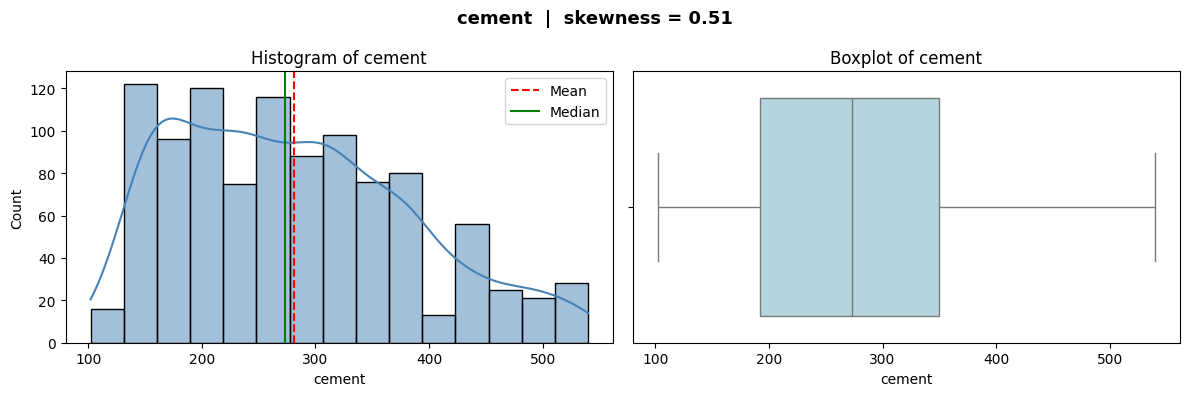

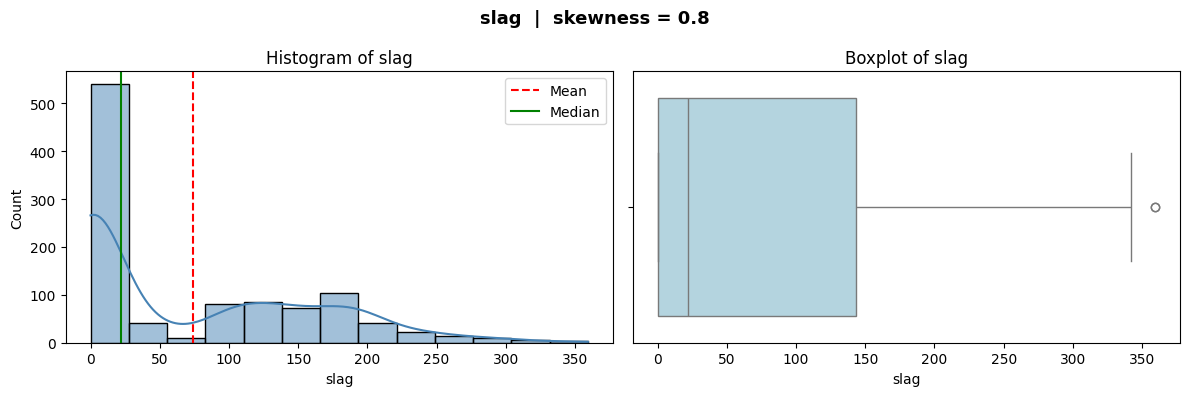

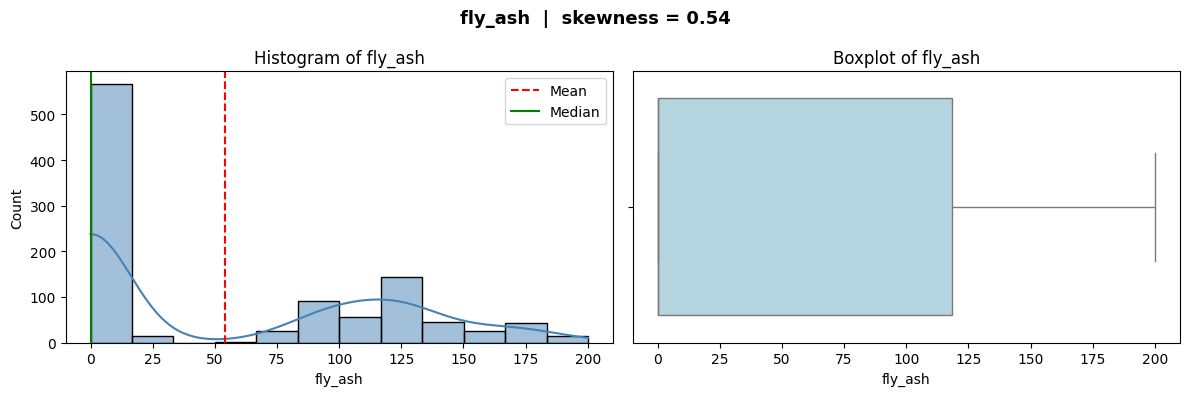

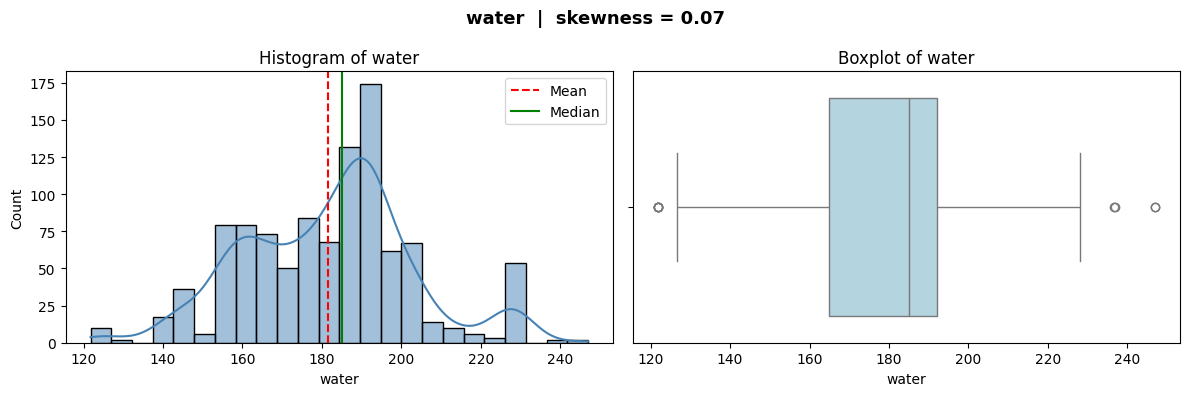

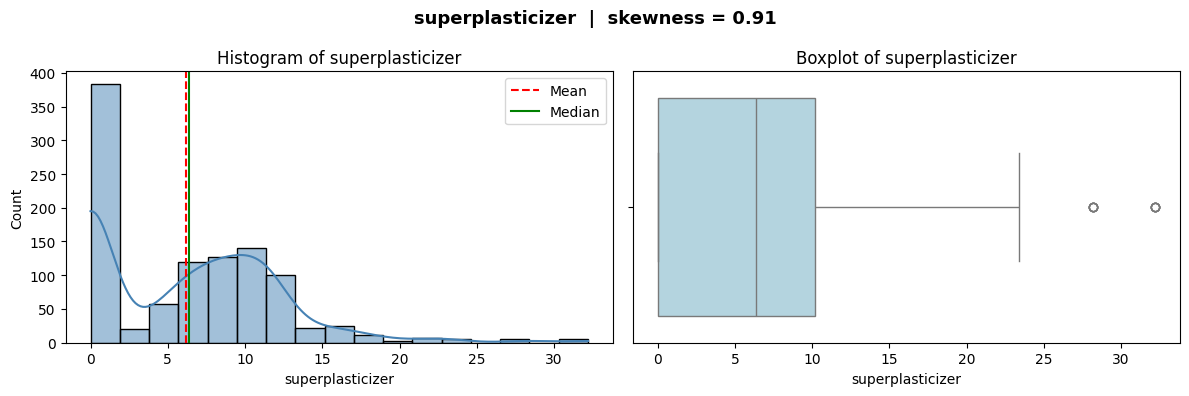

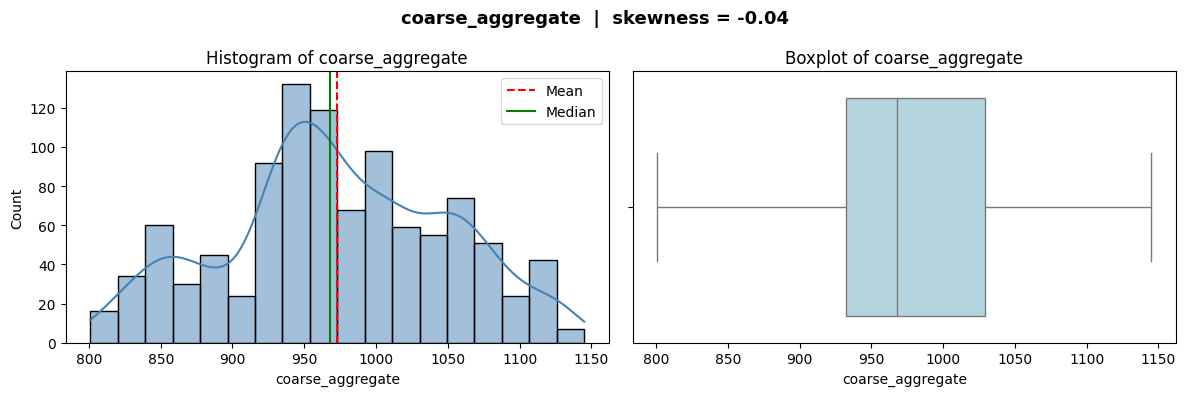

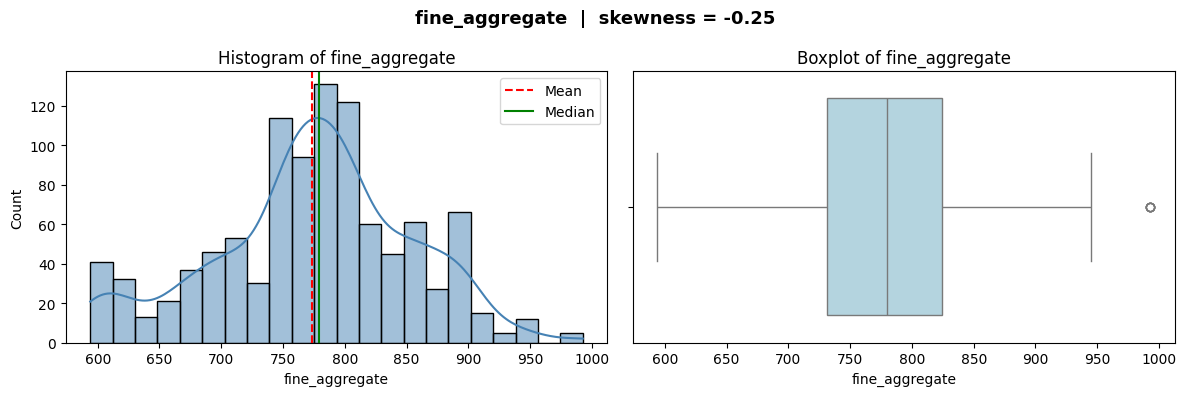

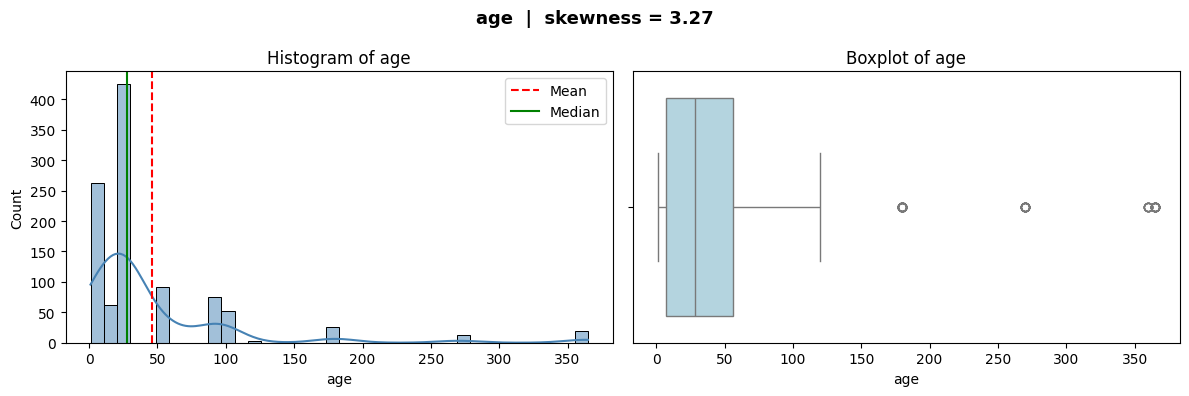

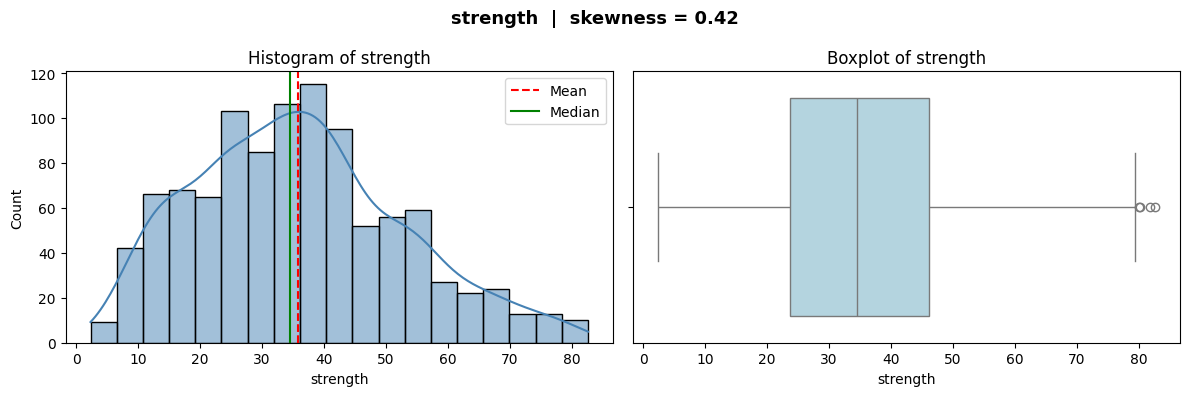

In [10]:
for col in df.columns:
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    # Left: histogram with KDE curve
    sns.histplot(df[col], kde=True, ax=axes[0], color="steelblue")
    axes[0].axvline(df[col].mean(), color="red", linestyle="--", label="Mean")
    axes[0].axvline(df[col].median(), color="green", linestyle="-", label="Median")
    axes[0].set_title("Histogram of " + col)
    axes[0].legend()

    # Right: boxplot
    sns.boxplot(x=df[col], ax=axes[1], color="lightblue")
    axes[1].set_title("Boxplot of " + col)

    plt.suptitle(col + "  |  skewness = " + str(round(df[col].skew(), 2)),
                 fontsize=13, fontweight="bold")
    plt.tight_layout()
    plt.show()

In [11]:
zero_cols = ["slag", "fly_ash", "superplasticizer"]

rows = []

for col in zero_cols:
    without = df[df[col] == 0]["strength"]   # mixes that don't use this ingredient
    with_ing = df[df[col] > 0]["strength"]   # mixes that use this ingredient

    rows.append({
        "ingredient": col,
        "count_without": len(without),
        "count_with": len(with_ing),
        "percent_zero": len(without) / len(df) * 100,
        "mean_without": without.mean(),
        "mean_with": with_ing.mean(),
        "median_without": without.median(),
        "median_with": with_ing.median(),
        "difference": with_ing.mean() - without.mean(),
    })

zero_summary = pd.DataFrame(rows).set_index("ingredient").round(2)
zero_summary

,count_without,count_with,percent_zero,mean_without,mean_with,median_without,median_with,difference
ingredient,,,,,,,,
slag,466,564,45.24,31.66,39.26,31.35,37.98,7.60
fly_ash,566,464,54.95,36.77,34.65,35.30,33.74,-2.12
superplasticizer,379,651,36.80,29.52,39.49,28.02,37.92,9.97


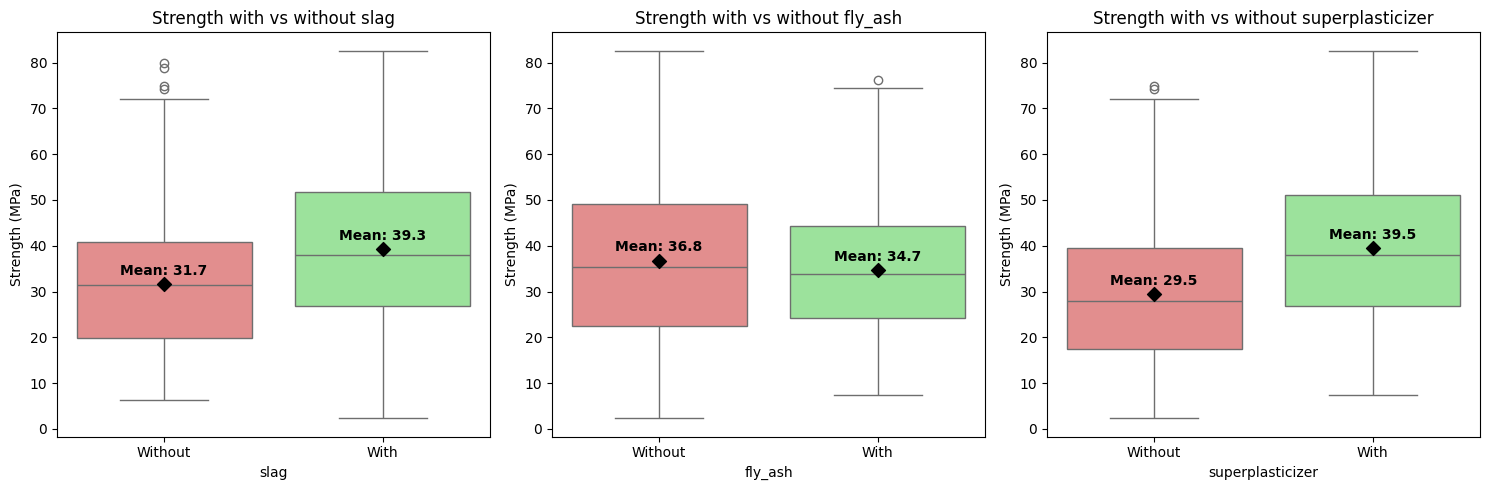

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for i, col in enumerate(zero_cols):
    # Label each row as "With" or "Without" this ingredient
    group = df[col].apply(lambda x: "With" if x > 0 else "Without")

    sns.boxplot(x=group, y=df["strength"], order=["Without", "With"],
                hue=group, hue_order=["Without", "With"],
                palette=["lightcoral", "lightgreen"], legend=False, ax=axes[i])

    # Mark the mean with a black diamond and write its value
    means = df.groupby(group)["strength"].mean()
    for j, label in enumerate(["Without", "With"]):
        axes[i].scatter(j, means[label], color="black", marker="D", s=50, zorder=3)
        axes[i].text(j, means[label] + 2, "Mean: " + str(round(means[label], 1)),
                     ha="center", fontweight="bold")

    axes[i].set_title("Strength with vs without " + col)
    axes[i].set_xlabel(col)
    axes[i].set_ylabel("Strength (MPa)")

plt.tight_layout()
plt.show()

In [13]:
# Sorted list of the 14 age values
age_order = sorted(df["age"].unique())

# Make an ordered categorical version of age (df itself is not changed)
age_cat = pd.Categorical(df["age"], categories=age_order, ordered=True)

print("Age categories:", age_order)
print("Number of categories:", len(age_order))

Age categories: [np.int64(1), np.int64(3), np.int64(7), np.int64(14), np.int64(28), np.int64(56), np.int64(90), np.int64(91), np.int64(100), np.int64(120), np.int64(180), np.int64(270), np.int64(360), np.int64(365)]
Number of categories: 14


In [14]:
age_summary = df.groupby("age")["strength"].agg(["count", "mean", "median", "std", "min", "max"]).round(2)
age_summary

,count,mean,median,std,min,max
age,,,,,,
1,2,9.45,9.45,4.50,6.27,12.64
3,134,18.98,15.72,9.86,2.33,41.64
7,126,26.05,21.65,14.58,7.51,59.09
14,62,28.75,26.54,8.64,12.84,59.76
28,425,36.75,33.76,14.71,8.54,81.75
56,91,51.89,51.72,14.31,23.25,80.20
90,54,40.48,39.68,9.82,21.86,69.66
91,22,69.81,67.95,7.70,56.50,82.60
100,52,47.67,46.98,8.40,33.54,66.95


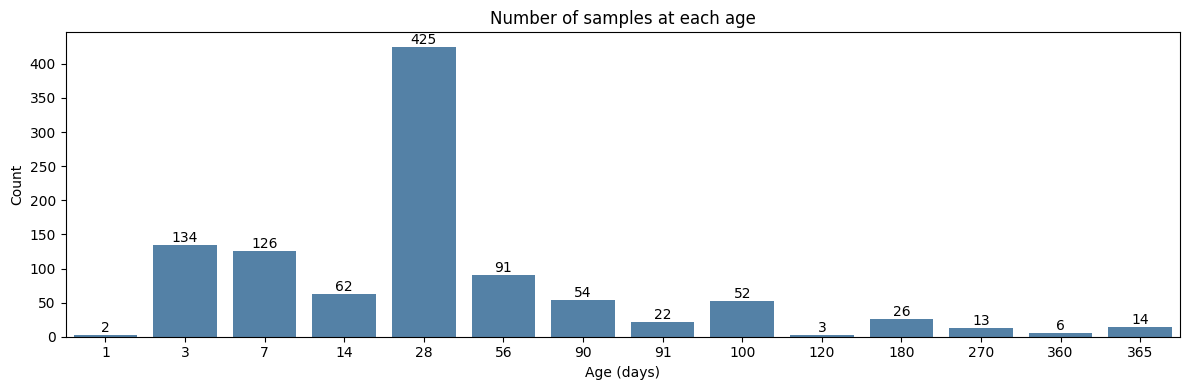

In [15]:
plt.figure(figsize=(12, 4))
ax = sns.countplot(x=age_cat, color="steelblue")
ax.bar_label(ax.containers[0])   # write the count on top of each bar

plt.title("Number of samples at each age")
plt.xlabel("Age (days)")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

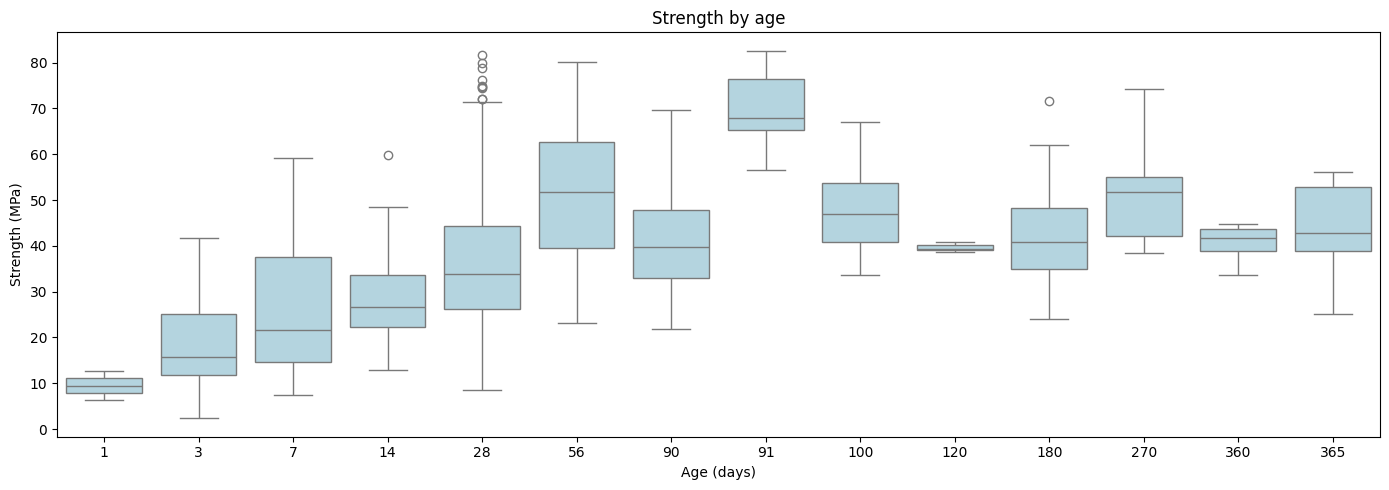

In [16]:
plt.figure(figsize=(14, 5))
sns.boxplot(x=age_cat, y=df["strength"], color="lightblue")

plt.title("Strength by age")
plt.xlabel("Age (days)")
plt.ylabel("Strength (MPa)")
plt.tight_layout()
plt.show()

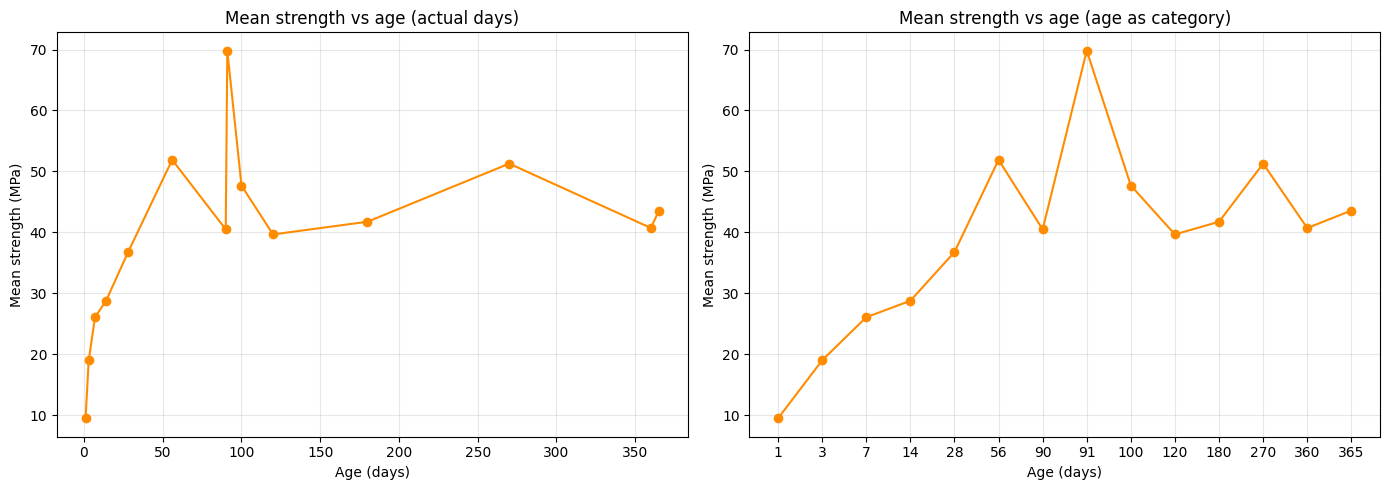

In [17]:
mean_strength = df.groupby("age")["strength"].mean()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left: real time scale (days)
axes[0].plot(mean_strength.index, mean_strength.values, marker="o", color="darkorange")
axes[0].set_title("Mean strength vs age (actual days)")
axes[0].set_xlabel("Age (days)")
axes[0].set_ylabel("Mean strength (MPa)")
axes[0].grid(True, alpha=0.3)

# Right: age as category (evenly spaced)
positions = range(len(age_order))
axes[1].plot(positions, mean_strength.values, marker="o", color="darkorange")
axes[1].set_xticks(positions)
axes[1].set_xticklabels(age_order)
axes[1].set_title("Mean strength vs age (age as category)")
axes[1].set_xlabel("Age (days)")
axes[1].set_ylabel("Mean strength (MPa)")
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

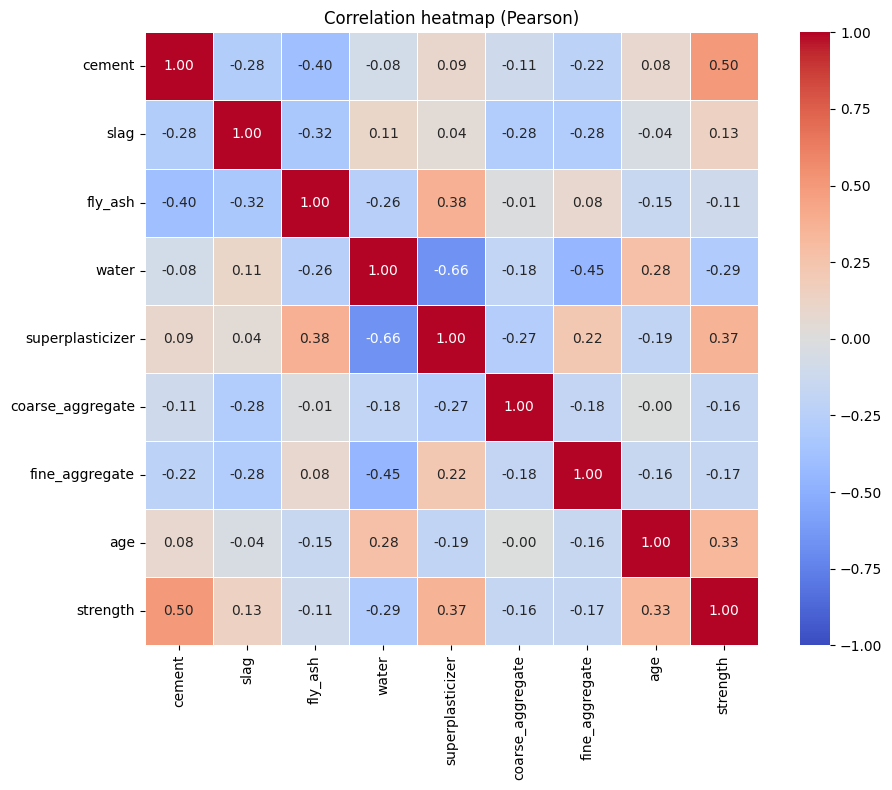

In [18]:
# Correlation heatmap
# All columns except the target
features = df.columns.drop("strength")

corr = df.corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm",
            vmin=-1, vmax=1, square=True, linewidths=0.5)
plt.title("Correlation heatmap (Pearson)")
plt.tight_layout()
plt.show()

                  pearson  spearman  difference
cement              0.498     0.478      -0.020
superplasticizer    0.366     0.348      -0.019
age                 0.329     0.596       0.267
slag                0.135     0.162       0.028
fly_ash            -0.106    -0.078       0.028
coarse_aggregate   -0.165    -0.184      -0.019
fine_aggregate     -0.167    -0.180      -0.013
water              -0.290    -0.308      -0.019


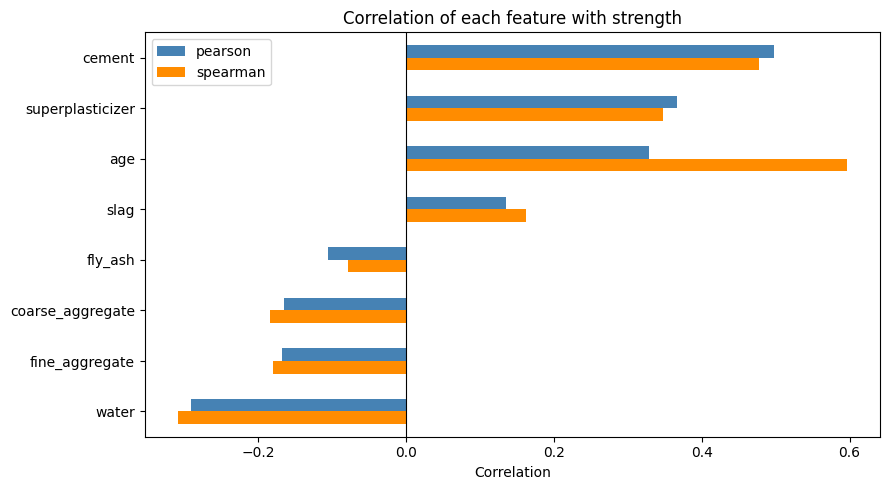

In [19]:
# Correlation with strength (Pearson vs Spearman)
# Pearson = straight-line relationship, Spearman = any steady (monotonic) trend
pearson = df.corr(method="pearson")["strength"].drop("strength")
spearman = df.corr(method="spearman")["strength"].drop("strength")

corr_table = pd.DataFrame({"pearson": pearson, "spearman": spearman})
corr_table["difference"] = corr_table["spearman"] - corr_table["pearson"]
corr_table = corr_table.sort_values("pearson", ascending=False).round(3)
print(corr_table)

corr_table[["pearson", "spearman"]].plot(kind="barh", figsize=(9, 5),
                                         color=["steelblue", "darkorange"])
plt.axvline(0, color="black", linewidth=0.8)
plt.title("Correlation of each feature with strength")
plt.xlabel("Correlation")
plt.gca().invert_yaxis()   # strongest at the top
plt.tight_layout()
plt.show()

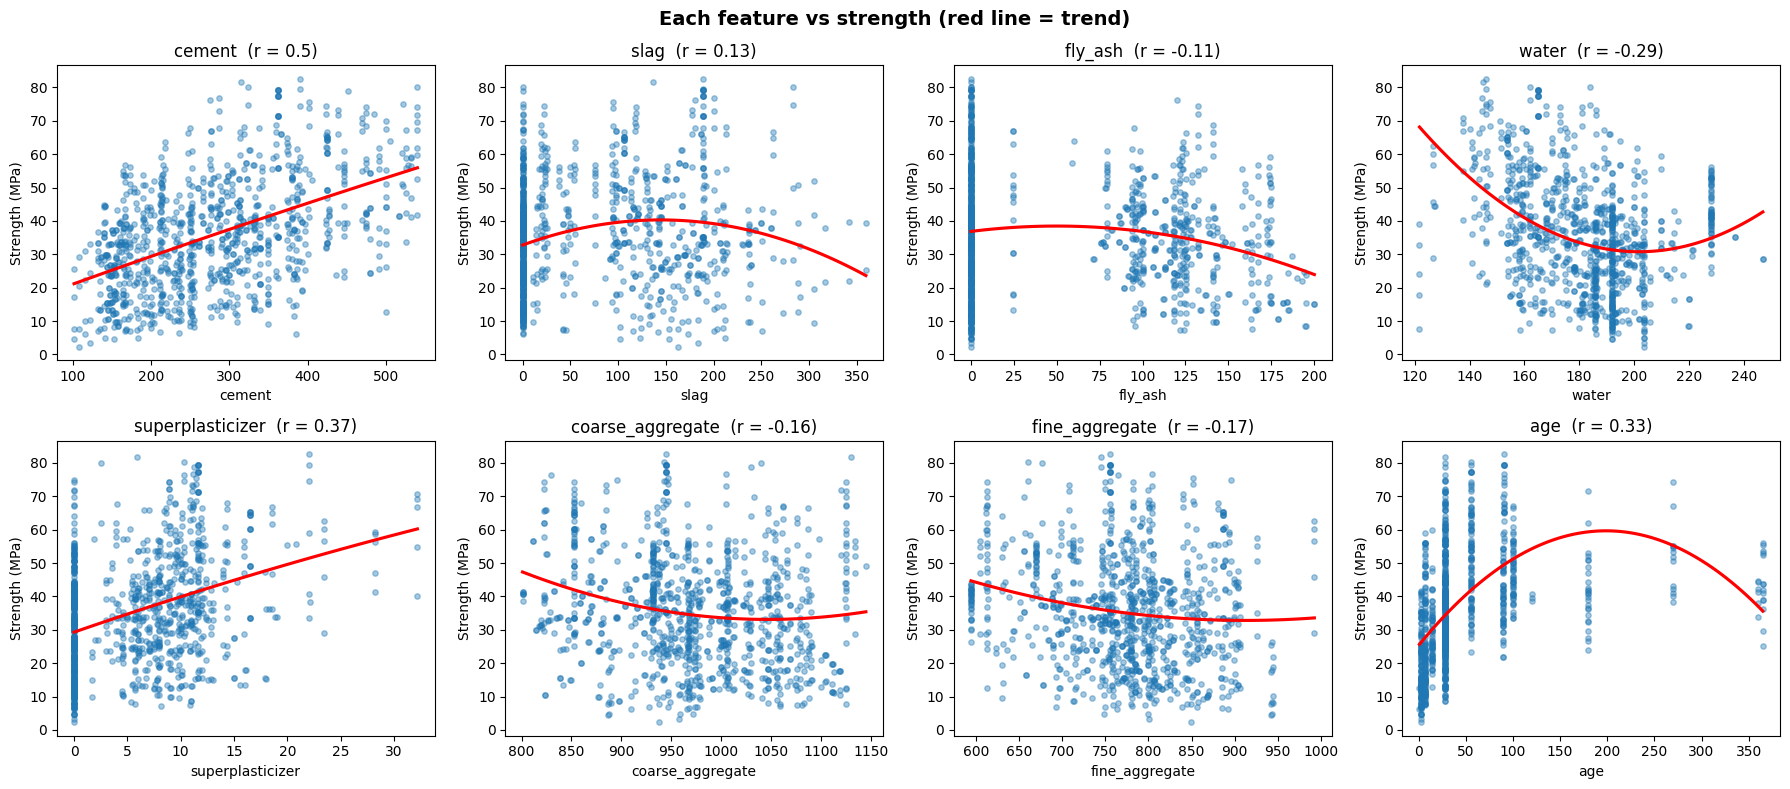

In [20]:
# Scatter plot of each feature vs strength
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
axes = axes.flatten()

for i, col in enumerate(features):
    # order=2 draws a curved trend line, so nonlinear patterns show up
    sns.regplot(x=df[col], y=df["strength"], ax=axes[i], order=2, ci=None,
                scatter_kws={"alpha": 0.4, "s": 15}, line_kws={"color": "red"})
    r = round(df[col].corr(df["strength"]), 2)
    axes[i].set_title(col + "  (r = " + str(r) + ")")
    axes[i].set_ylabel("Strength (MPa)")

plt.suptitle("Each feature vs strength (red line = trend)", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

Correlation with strength:
water/cement : -0.501
water/binder : -0.623
log(age)     : 0.552


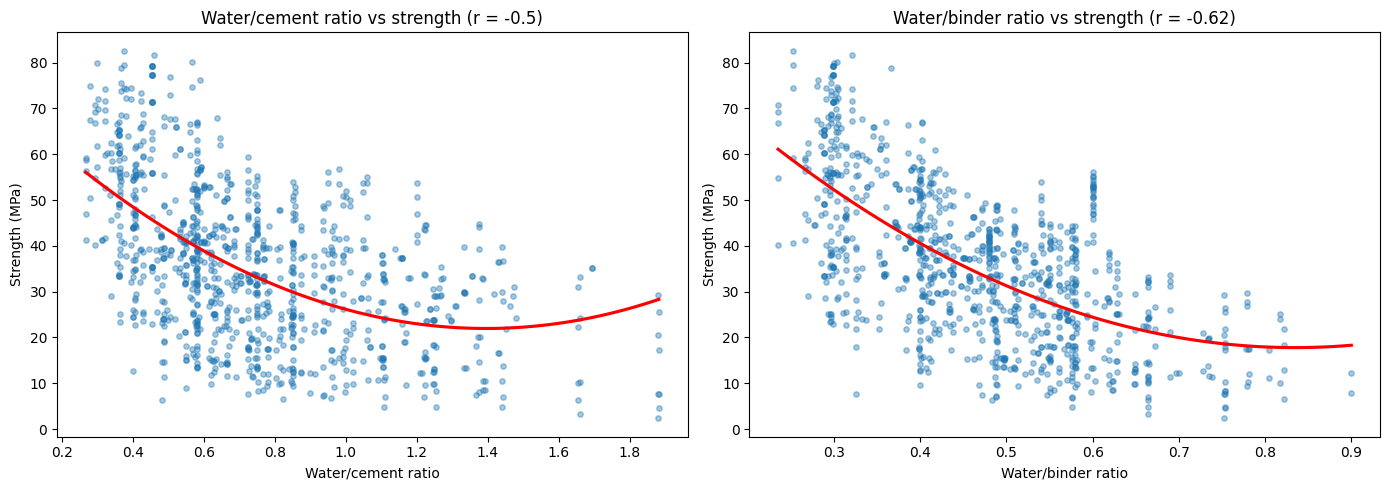

In [21]:
# Water/cement and water/binder ratio vs strength
# Calculated as separate variables, so df is not changed
wc_ratio = df["water"] / df["cement"]
binder = df["cement"] + df["slag"] + df["fly_ash"]
wb_ratio = df["water"] / binder

print("Correlation with strength:")
print("water/cement :", round(wc_ratio.corr(df["strength"]), 3))
print("water/binder :", round(wb_ratio.corr(df["strength"]), 3))
print("log(age)     :", round(np.log(df["age"]).corr(df["strength"]), 3))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.regplot(x=wc_ratio, y=df["strength"], ax=axes[0], order=2, ci=None,
            scatter_kws={"alpha": 0.4, "s": 15}, line_kws={"color": "red"})
axes[0].set_title("Water/cement ratio vs strength (r = " + str(round(wc_ratio.corr(df["strength"]), 2)) + ")")
axes[0].set_xlabel("Water/cement ratio")
axes[0].set_ylabel("Strength (MPa)")

sns.regplot(x=wb_ratio, y=df["strength"], ax=axes[1], order=2, ci=None,
            scatter_kws={"alpha": 0.4, "s": 15}, line_kws={"color": "red"})
axes[1].set_title("Water/binder ratio vs strength (r = " + str(round(wb_ratio.corr(df["strength"]), 2)) + ")")
axes[1].set_xlabel("Water/binder ratio")
axes[1].set_ylabel("Strength (MPa)")

plt.tight_layout()
plt.show()

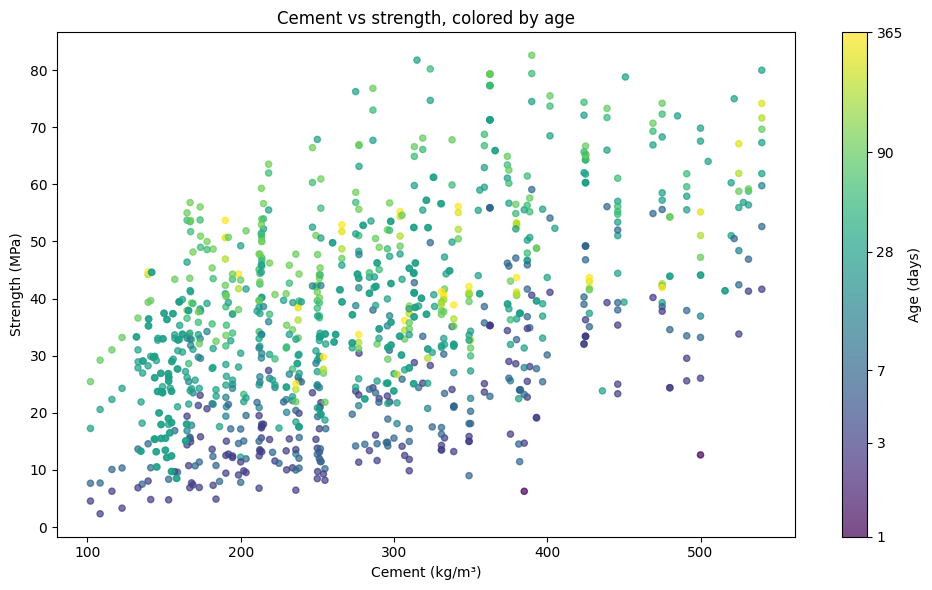

In [22]:
# Cement vs strength, colored by age
plt.figure(figsize=(10, 6))

# Color by log(age), so young and old samples are easy to tell apart
sc = plt.scatter(df["cement"], df["strength"], c=np.log(df["age"]),
                 cmap="viridis", alpha=0.7, s=20)

cbar = plt.colorbar(sc)
cbar.set_ticks(np.log([1, 3, 7, 28, 90, 365]))
cbar.set_ticklabels([1, 3, 7, 28, 90, 365])
cbar.set_label("Age (days)")

plt.title("Cement vs strength, colored by age")
plt.xlabel("Cement (kg/m³)")
plt.ylabel("Strength (MPa)")
plt.tight_layout()
plt.show()

cement
(101.999, 213.76]    344
(213.76, 321.3]      342
(321.3, 540.0]       344
Name: count, dtype: int64


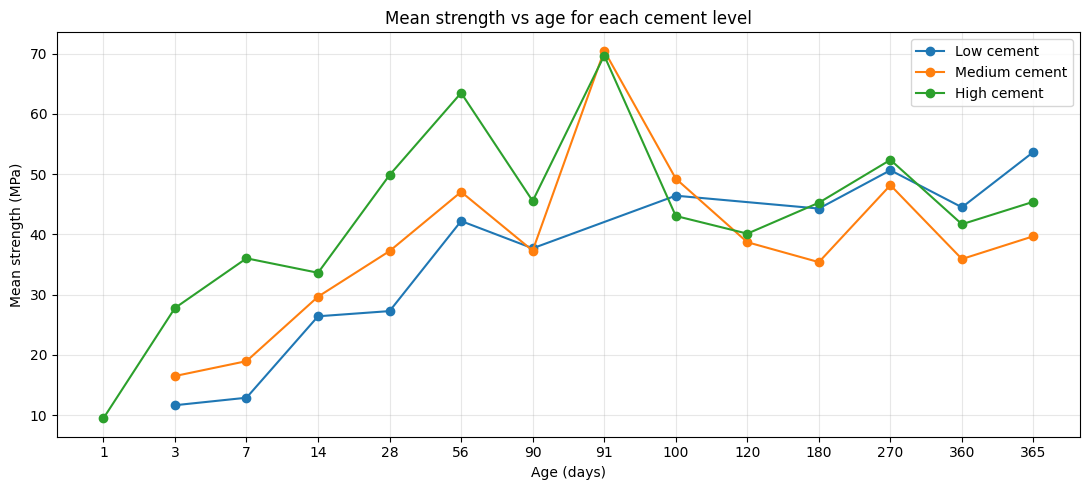

In [23]:
# Strength vs age for each cement level
# Split cement into 3 equal-size groups
cement_group = pd.qcut(df["cement"], q=3, labels=["Low cement", "Medium cement", "High cement"])
print(pd.qcut(df["cement"], q=3).value_counts().sort_index())

plt.figure(figsize=(11, 5))

for group in ["Low cement", "Medium cement", "High cement"]:
    mean_by_age = df[cement_group == group].groupby("age")["strength"].mean()
    positions = [age_order.index(a) for a in mean_by_age.index]
    plt.plot(positions, mean_by_age.values, marker="o", label=group)

plt.xticks(range(len(age_order)), age_order)
plt.title("Mean strength vs age for each cement level")
plt.xlabel("Age (days)")
plt.ylabel("Mean strength (MPa)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

Number of samples in each cell:
age            Early (1-7)  Standard (14-28)  Late (56-365)
cement                                                     
Low cement              72               192             80
Medium cement           77               173             92
High cement            113               122            109


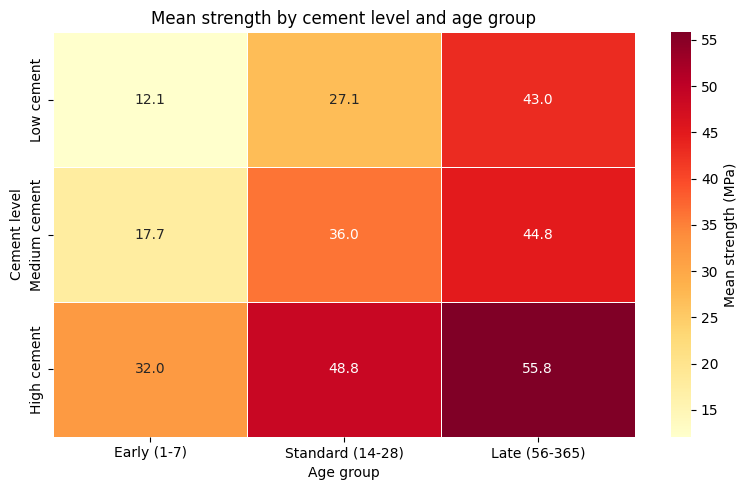

In [24]:
# Heatmap of cement level × age group
age_group = pd.cut(df["age"], bins=[0, 7, 28, 365],
                   labels=["Early (1-7)", "Standard (14-28)", "Late (56-365)"])

pivot = df.pivot_table(values="strength", index=cement_group, columns=age_group,
                       aggfunc="mean", observed=False).round(1)

counts = df.pivot_table(values="strength", index=cement_group, columns=age_group,
                        aggfunc="count", observed=False)
print("Number of samples in each cell:")
print(counts)

plt.figure(figsize=(8, 5))
sns.heatmap(pivot, annot=True, fmt=".1f", cmap="YlOrRd", linewidths=0.5,
            cbar_kws={"label": "Mean strength (MPa)"})
plt.title("Mean strength by cement level and age group")
plt.xlabel("Age group")
plt.ylabel("Cement level")
plt.tight_layout()
plt.show()

Samples at 28 days: 425
                  all_ages  only_28_days
cement               0.498         0.666
superplasticizer     0.366         0.213
slag                 0.135         0.141
coarse_aggregate    -0.165        -0.120
fine_aggregate      -0.167        -0.138
fly_ash             -0.106        -0.269
water               -0.290        -0.399


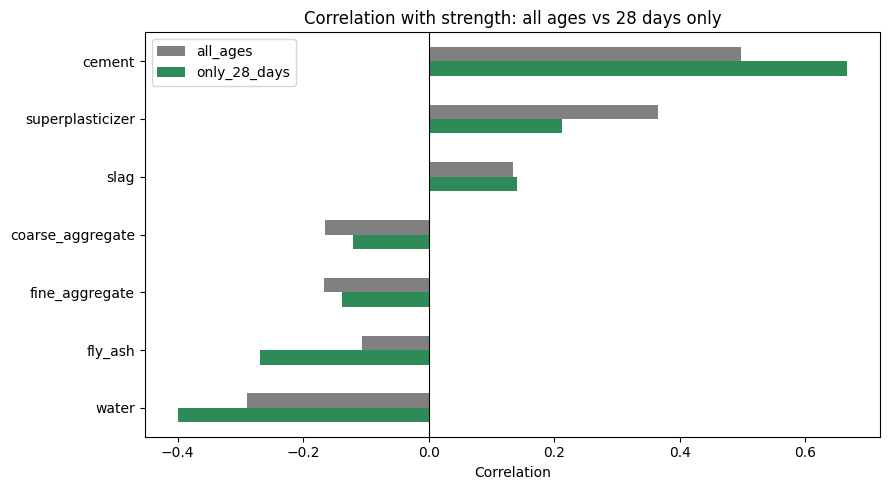

In [25]:
# Correlations at 28 days only (removes the effect of age)
df_28 = df[df["age"] == 28].drop(columns="age")
print("Samples at 28 days:", len(df_28))

corr_28 = df_28.corr()["strength"].drop("strength")
corr_all = df.drop(columns="age").corr()["strength"].drop("strength")

compare = pd.DataFrame({"all_ages": corr_all, "only_28_days": corr_28}).round(3)
compare = compare.sort_values("only_28_days", ascending=False)
print(compare)

compare.plot(kind="barh", figsize=(9, 5), color=["gray", "seagreen"])
plt.axvline(0, color="black", linewidth=0.8)
plt.title("Correlation with strength: all ages vs 28 days only")
plt.xlabel("Correlation")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [26]:
# Multicollinearity check (correlated pairs and VIF)
corr_features = df[features].corr()

# 1. Feature pairs with |correlation| > 0.5
pairs = []
for i in range(len(features)):
    for j in range(i + 1, len(features)):
        r = corr_features.iloc[i, j]
        if abs(r) > 0.5:
            pairs.append({"feature_1": features[i], "feature_2": features[j], "correlation": round(r, 3)})

print("Highly correlated pairs (|r| > 0.5):")
print(pd.DataFrame(pairs))
print()

# 2. VIF (Variance Inflation Factor): 1 = no problem, 5-10 = moderate, >10 = high
#    Simple formula: VIF = diagonal of the inverse correlation matrix
vif = pd.DataFrame({"feature": features,
                    "VIF": np.linalg.inv(corr_features.values).diagonal()})
vif = vif.sort_values("VIF", ascending=False).round(2)
print(vif)

Highly correlated pairs (|r| > 0.5):
  feature_1         feature_2  correlation
0     water  superplasticizer       -0.657

            feature   VIF
0            cement  7.49
1              slag  7.28
6    fine_aggregate  7.01
3             water  7.00
2           fly_ash  6.17
5  coarse_aggregate  5.08
4  superplasticizer  2.97
7               age  1.12
